# Deep Reinforcement Learning on Connect Four with OpenSpiel

**Deliverable 2 – Deep RL exploration.** We train a convolutional **Double DQN** agent through **self-play** on Connect Four (a 2-player, zero-sum, deterministic, perfect-information game from [OpenSpiel](https://github.com/google-deepmind/open_spiel)) and study how hyper-parameters change learning.

**Notebook roadmap**
1. Setup & environment exploration (state / action / reward)
2. Baselines (random player, MCTS player) and evaluation tools
3. The deep RL agent (Q-network, exploration policies, replay buffers incl. prioritized replay, training loop)
4. Experiments: exploration strategy, stability (ε / τ trade-off), prioritized replay, stochastic vs deterministic environment, seeding
5. Interpreting the agent (Q-value plots with arrows, tactical test suite, sample game)
6. Extension: a stronger agent (residual dueling network, mirror augmentation, look-ahead search) and export to the Streamlit web app (`app.py`)
7. Summary, references

> **Runtime tip:** set `QUICK = True` in the configuration cell for a fast smoke test (minutes). The full setup runs ~30 training runs; results are cached in `results/` so re-running a cell is instant. The strong agent of section 9 adds ~20 min on a Colab T4. Figures are saved in `figures/` (ready to reuse in your report and slides).

## 1. Setup

First install the dependencies. `open_spiel` provides the game and the MCTS baseline, `torch` the        neural network. OpenSpiel wheels exist for Linux/macOS; on Windows use WSL or Google Colab. Skip this cell if everything is already installed.

In [41]:
# Run once (uncomment). On Colab/Linux this is all that is needed.
!pip install -q open_spiel torch numpy pandas matplotlib

Now the imports, global switches and a seeding helper. `set_seed` seeds Python, NumPy and PyTorch together and forces deterministic GPU kernels, which is what makes our runs reproducible (we test this explicitly in section 6.6). `QUICK` shrinks the experiment so you can verify the whole notebook runs before launching the full study.

In [6]:
import os, random, time, pickle, textwrap, json
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # deterministic cuBLAS (must be set before CUDA starts)
from dataclasses import dataclass, replace
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

import pyspiel
from open_spiel.python.algorithms import mcts

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

QUICK = False                      # True = tiny smoke-test version of every experiment
EPISODES   = 600  if QUICK else 3000   # self-play games per training run
EVAL_EVERY = 100  if QUICK else 250    # evaluate every N episodes
EVAL_GAMES = 20   if QUICK else 40     # evaluation games per opponent
SEEDS      = [0, 1] if QUICK else [0, 1, 2]

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)  
    torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False   # same seed -> same run, also on GPU

Device: cuda


## 2. The environment: state, action, reward

We load Connect Four and print its key properties. The three RL ingredients map to OpenSpiel as follows: **state** = board (`state.observation_tensor()`, shape 3×6×7), **action** = the column to drop a disc in (7 discrete actions, `state.legal_actions()`), **reward** = `state.returns()` at the end of the game (+1 win / 0 draw / −1 loss; there is no intermediate reward).

In [7]:
game = pyspiel.load_game("connect_four")
print("Players              :", game.num_players())
print("Distinct actions     :", game.num_distinct_actions(), "(one per column)")
print("Observation shape    :", game.observation_tensor_shape())
print("Min / max utility    :", game.min_utility(), "/", game.max_utility())
print("Deterministic game   :", game.get_type().chance_mode)
print("Max game length      :", game.max_game_length(), "moves")

Players              : 2
Distinct actions     : 7 (one per column)
Observation shape    : [3, 6, 7]
Min / max utility    : -1.0 / 1.0
Deterministic game   : ChanceMode.DETERMINISTIC
Max game length      : 42 moves


Let's inspect one concrete state. We play three random moves and look at what the agent would observe: the board, the legal actions, the current player and the observation tensor. Note that a full column disappears from the legal actions – the agent must never select it, so we will **mask illegal actions** in all our policies and targets.

In [8]:
state = game.new_initial_state()
rng_demo = np.random.RandomState(0)
for _ in range(3):
    state.apply_action(int(rng_demo.choice(state.legal_actions())))

print(state)
print("Current player :", state.current_player())
print("Legal actions  :", state.legal_actions())
print("Terminal?      :", state.is_terminal())
print("Observation tensor shape:", np.array(state.observation_tensor(0)).reshape(3, 6, 7).shape)

.......
.......
.......
.......
.......
x...xo.

Current player : 1
Legal actions  : [0, 1, 2, 3, 4, 5, 6]
Terminal?      : False
Observation tensor shape: (3, 6, 7)


Here we play a complete random game to show the **reward** structure: it is zero at every step and only becomes non-zero when the game ends. This *sparse reward* is the main difficulty of the problem – the agent must propagate the final outcome backwards through ~20 moves (credit assignment).

In [9]:
state = game.new_initial_state()
n = 0
while not state.is_terminal():
    state.apply_action(int(rng_demo.choice(state.legal_actions())))
    n += 1
print(state)
print(f"Game ended after {n} moves. Returns (player0, player1) = {state.returns()}")

.......
.......
.o.x...
xo.x..o
xoxooxx
ooxxoox

Game ended after 20 moves. Returns (player0, player1) = [-1.0, 1.0]


### 2.1 Observation encoding (player-relative)

OpenSpiel's tensor is *absolute* (one plane per player). For self-play with a **single shared network** it is much easier if the network always sees the board from the point of view of the player to move: plane 0 = my discs, plane 1 = opponent discs, plane 2 = empty. We first *calibrate* which OpenSpiel plane belongs to which player (so we don't depend on an internal ordering), then define `encode(state)`.

In [10]:
def _calibrate_planes():
    s = game.new_initial_state()
    empty_t = np.array(s.observation_tensor(0)).reshape(3, 6, 7)
    EMPTY = int(np.argmax(empty_t.sum(axis=(1, 2))))          # the plane that is full of 1s initially
    s.apply_action(3)                                         # player 0 plays column 3
    t = np.array(s.observation_tensor(0)).reshape(3, 6, 7)
    P0 = [i for i in range(3) if i != EMPTY and t[i].sum() == 1][0]
    P1 = [i for i in range(3) if i not in (EMPTY, P0)][0]
    return P0, P1, EMPTY

P0_PLANE, P1_PLANE, EMPTY_PLANE = _calibrate_planes()
print("planes -> player0:", P0_PLANE, "player1:", P1_PLANE, "empty:", EMPTY_PLANE)

def encode(state):
    # (3,6,7) float32: [my discs, opponent discs, empty], from the view of the player to move
    t = np.asarray(state.observation_tensor(0), dtype=np.float32).reshape(3, 6, 7)
    me = state.current_player()
    mine = t[P0_PLANE] if me == 0 else t[P1_PLANE]
    theirs = t[P1_PLANE] if me == 0 else t[P0_PLANE]
    return np.stack([mine, theirs, t[EMPTY_PLANE]])

def legal_mask(state):
    m = np.zeros(7, dtype=bool); m[state.legal_actions()] = True
    return m

print("encode(initial) shape:", encode(game.new_initial_state()).shape)

planes -> player0: 0 player1: 1 empty: 2
encode(initial) shape: (3, 6, 7)


## 3. Baseline opponents and evaluation tools

To know whether the agent is learning we need fixed reference opponents. A **random player** gives the lowest bar (and reveals the first-player advantage). An **MCTS player** (OpenSpiel's UCT with random rollouts, `n` simulations per move) is a much stronger and tunable opponent. Every bot is simply a function `state -> action`.

In [11]:
def make_random_bot(seed):
    rng = np.random.RandomState(seed)
    return lambda s: int(rng.choice(s.legal_actions()))

def make_mcts_bot(sims, seed):
    rng = np.random.RandomState(seed)
    evaluator = mcts.RandomRolloutEvaluator(n_rollouts=1, random_state=rng)
    bot = mcts.MCTSBot(game, uct_c=2.0, max_simulations=sims, evaluator=evaluator, random_state=rng)
    return lambda s: int(bot.step(s))

`evaluate` plays `n_games` between our agent and an opponent, **alternating who moves first** (Connect Four is a first-player win, so ignoring colour would bias the result). It returns wins/draws/losses from the agent's perspective and a single `score = (wins + 0.5·draws) / games`, where 0.5 is "equal strength" and 1.0 is a perfect result.

In [12]:
def evaluate(agent_bot, opp_bot, n_games):
    w = d = l = 0
    for g in range(n_games):
        agent_first = (g % 2 == 0)
        s = game.new_initial_state()
        while not s.is_terminal():
            agent_turn = (s.current_player() == 0) == agent_first
            s.apply_action(agent_bot(s) if agent_turn else opp_bot(s))
        r = s.returns()[0 if agent_first else 1]
        if r > 0: w += 1
        elif r < 0: l += 1
        else: d += 1
    return dict(win=w, draw=d, loss=l, score=(w + 0.5 * d) / n_games)

# Reference numbers: random vs random, and MCTS vs random.
print("random  vs random :", evaluate(make_random_bot(1), make_random_bot(2), 200))
print("MCTS-20 vs random :", evaluate(make_mcts_bot(20, 3), make_random_bot(4), 20))
print("MCTS-100 vs random:", evaluate(make_mcts_bot(100, 5), make_random_bot(6), 20))

random  vs random : {'win': 104, 'draw': 0, 'loss': 96, 'score': 0.52}
MCTS-20 vs random : {'win': 19, 'draw': 0, 'loss': 1, 'score': 0.95}
MCTS-100 vs random: {'win': 20, 'draw': 0, 'loss': 0, 'score': 1.0}


### 3.1 A tactical test suite (a diagnostic metric)

Win rate vs random is a noisy, indirect signal. To test *what* the agent understands, we build two sets of positions from random play, each with a known correct answer: **win-in-1** (an immediate winning move exists – take it) and **forced defence** (the opponent threatens to win next move and exactly one move avoids that – block it). Accuracy on these sets is cheap to compute during training and lets us watch concepts such as "complete four in a row" and "block the opponent" being learned. We also keep the encoded tensors so the check is a single batched forward pass.

In [13]:
def opponent_can_win(ns):
    # ns = state after our move; can the player now to move win immediately?
    if ns.is_terminal(): return False
    me = ns.current_player()
    for b in ns.legal_actions():
        c = ns.child(b)
        if c.is_terminal() and c.returns()[me] > 0: return True
    return False

def build_tactical_suite(n_each=100, seed=123, max_tries=15000):
    rng = np.random.RandomState(seed)
    wins, blocks, tries = [], [], 0
    while (len(wins) < n_each or len(blocks) < n_each) and tries < max_tries:
        tries += 1
        s = game.new_initial_state()
        for _ in range(rng.randint(6, 30)):
            if s.is_terminal(): break
            s.apply_action(int(rng.choice(s.legal_actions())))
        if s.is_terminal(): continue
        p, legal = s.current_player(), s.legal_actions()
        winning = [a for a in legal if s.child(a).is_terminal() and s.child(a).returns()[p] > 0]
        if winning:
            if len(wins) < n_each: wins.append((s.clone(), winning))
            continue
        safe = [a for a in legal if not opponent_can_win(s.child(a))]
        if len(safe) == 1 and len(legal) > 1 and len(blocks) < n_each:
            blocks.append((s.clone(), safe))
    return wins, blocks

def pack(items):
    obs = np.stack([encode(s) for s, _ in items]).astype(np.float32)
    ok = np.zeros((len(items), 7), dtype=bool); lm = np.zeros((len(items), 7), dtype=bool)
    for i, (s, acts) in enumerate(items):
        ok[i, acts] = True; lm[i] = legal_mask(s)
    return dict(items=items, obs=torch.tensor(obs), ok=ok, legal=lm)

WINS, BLOCKS = build_tactical_suite()
TACT = {"win": pack(WINS), "block": pack(BLOCKS)}
print(f"Built {len(WINS)} win-in-1 and {len(BLOCKS)} forced-defence positions.")
print("Chance level (random legal move): win-in-1 ≈ %.2f, forced defence ≈ %.2f" % (
    np.mean([1 / len(s.legal_actions()) * len(a) for s, a in WINS]),
    np.mean([1 / len(s.legal_actions()) * len(a) for s, a in BLOCKS])))

Built 100 win-in-1 and 100 forced-defence positions.
Chance level (random legal move): win-in-1 ≈ 0.21, forced defence ≈ 0.15


## 4. The deep RL agent

### 4.1 Hyper-parameters

All settings live in one `Config` dataclass so every experiment is just "the baseline with some fields replaced". Key groups: **learning** (`gamma`, `lr`, `batch_size`, `target_update`), **exploration** (`explore` = `'eps'` ε-greedy with exponential decay or `'boltz'` Boltzmann/softmax with temperature annealing; `eps_*` and `tau_*` schedules, measured in *episodes*), **replay** (`per` toggles Prioritized Experience Replay with exponent `per_alpha` and importance-sampling start `per_beta0`), **environment** (`slip_prob` makes the environment stochastic), **extension** (`net`, `mirror`, used in section 9) and **evaluation**.

In [14]:
@dataclass
class Config:
    episodes: int = EPISODES
    gamma: float = 0.99
    lr: float = 1e-3
    batch_size: int = 64
    buffer_size: int = 50_000
    warmup: int = 1_000            # transitions collected before learning starts
    train_every: int = 4           # one gradient step every N environment steps
    target_update: int = 500       # hard target-network sync every N environment steps
    explore: str = "eps"           # 'eps' (epsilon-greedy) or 'boltz' (softmax)
    eps_start: float = 1.0
    eps_end: float = 0.05
    eps_decay: float = 0.27 * EPISODES   # exponential time-constant (episodes)
    tau_start: float = 1.0
    tau_end: float = 0.05
    tau_decay: float = 0.27 * EPISODES
    per: bool = False              # prioritized experience replay
    per_alpha: float = 0.6
    per_beta0: float = 0.4
    slip_prob: float = 0.0         # prob. that a chosen move is replaced by a random legal move
    net: str = "small"             # 'small' = QNet (4.2) or 'resnet' = residual dueling net (9.1)
    mirror: bool = False           # also store the left-right mirrored transition (9.2)
    eval_every: int = EVAL_EVERY
    eval_games: int = EVAL_GAMES
    mcts_eval_games: int = 0       # >0 also evaluates vs MCTS (slow)
    mcts_eval_sims: int = 20

BASE = Config(warmup=300 if QUICK else 1000)

def settings_str(cfg, keys=None):
    keys = keys or ["episodes", "gamma", "lr", "batch_size", "explore", "eps_decay", "eps_end",
                    "tau_decay", "tau_end", "per", "slip_prob"]
    return ", ".join(f"{k}={getattr(cfg, k):g}" if isinstance(getattr(cfg, k), (int, float)) and not isinstance(getattr(cfg, k), bool)
                     else f"{k}={getattr(cfg, k)}" for k in keys)
print(settings_str(BASE))

episodes=3000, gamma=0.99, lr=0.001, batch_size=64, explore=eps, eps_decay=810, eps_end=0.05, tau_decay=810, tau_end=0.05, per=False, slip_prob=0


### 4.2 Model architecture

A small **convolutional Q-network**: three 3×3 conv layers (64 filters) detect local patterns such as pairs, triples and open fours in any direction; their output is flattened into a 128-unit dense layer and a final linear layer outputs one **Q-value per column** (7 outputs). Q-values live in [−1, 1] because the only reward is ±1/0. Convolutions share weights across the board, which is a good inductive bias for a game defined by translation-invariant patterns.    

In [15]:
class QNet(nn.Module):
    def __init__(self, ch=64, hidden=128):
        super().__init__()
        self.c1 = nn.Conv2d(3, ch, 3, padding=1)
        self.c2 = nn.Conv2d(ch, ch, 3, padding=1)
        self.c3 = nn.Conv2d(ch, ch, 3, padding=1)
        self.fc1 = nn.Linear(ch * 6 * 7, hidden)
        self.out = nn.Linear(hidden, 7)

    def forward(self, x):
        x = F.relu(self.c1(x)); x = F.relu(self.c2(x)); x = F.relu(self.c3(x))
        return self.out(F.relu(self.fc1(x.flatten(1))))

NETS = {"small": QNet}             # Config.net -> class; section 9 adds the residual dueling net

print(QNet())
print("Parameters:", sum(p.numel() for p in QNet().parameters()))

QNet(
  (c1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (c2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (c3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=2688, out_features=128, bias=True)
  (out): Linear(in_features=128, out_features=7, bias=True)
)
Parameters: 420743


### 4.3 Replay buffers (uniform and prioritized)

Both buffers store `(observation, action, reward, next observation, next legal-action mask, done)`. The **uniform** buffer samples transitions at random, breaking temporal correlation. The **prioritized** buffer (Schaul et al., 2016) samples transition *i* with probability ∝ |TD-error|^α, so surprising transitions – in Connect Four typically the rare ones near a win or loss – are replayed more often. Because this biases the gradient, each sample gets an importance weight (N·P(i))^(−β)/max, with β annealed towards 1. We use a simple array-based implementation (clear rather than fast).

In [16]:
class ReplayBuffer:
    def __init__(self, capacity, seed, per=False, alpha=0.6):
        self.cap, self.per, self.alpha = capacity, per, alpha
        self.rng = np.random.RandomState(seed)
        self.obs = np.zeros((capacity, 3, 6, 7), np.float32)
        self.nobs = np.zeros((capacity, 3, 6, 7), np.float32)
        self.act = np.zeros(capacity, np.int64)
        self.rew = np.zeros(capacity, np.float32)
        self.done = np.zeros(capacity, np.float32)
        self.nmask = np.zeros((capacity, 7), bool)
        self.prio = np.ones(capacity, np.float32)
        self.ptr, self.size = 0, 0

    def add(self, o, a, r, no, nm, d):
        i = self.ptr
        self.obs[i], self.act[i], self.rew[i], self.nobs[i], self.nmask[i], self.done[i] = o, a, r, no, nm, d
        self.prio[i] = self.prio[:self.size].max() if self.size > 0 else 1.0   # new samples get max priority
        self.ptr = (self.ptr + 1) % self.cap
        self.size = min(self.size + 1, self.cap)

    def sample(self, batch, beta):
        if self.per:
            p = self.prio[:self.size] ** self.alpha
            p /= p.sum()
            idx = self.rng.choice(self.size, batch, p=p)
            w = (self.size * p[idx]) ** (-beta)
            w = (w / w.max()).astype(np.float32)
        else:
            idx = self.rng.randint(0, self.size, batch)
            w = np.ones(batch, np.float32)
        t = lambda x: torch.as_tensor(x[idx], device=device)
        return t(self.obs), t(self.act), t(self.rew), t(self.nobs), t(self.nmask), t(self.done), \
               torch.as_tensor(w, device=device), idx

    def update_priorities(self, idx, td_abs):
        if self.per: self.prio[idx] = td_abs + 1e-3

    def __len__(self): return self.size

### 4.4 The agent: exploration policies and the learning update

**Exploration.** ε-greedy picks a random legal move with probability ε(t) = ε_end + (ε_start − ε_end)·exp(−t/decay), otherwise the greedy move. Boltzmann samples a legal move with probability softmax(Q/τ(t)) with the same annealing shape, so good moves are favoured *proportionally* instead of uniformly-random exploration. Both always respect the legal-action mask.

**Learning (Double DQN, negamax form).** Connect Four is zero-sum and the network always sees the board from the mover's perspective, so the opponent's value is the *negative* of ours: target `y = r − γ · Q_target(s', argmax_a' Q_online(s', a'))` over legal `a'`, and `y = r` at terminal states. The action is chosen by the online net and evaluated by the target net (Double DQN, reduces over-estimation). Loss is Huber, weighted by importance weights when PER is on.

In [17]:
class DQNAgent:
    def __init__(self, cfg, seed):
        self.cfg = cfg
        self.rng = np.random.RandomState(seed + 1000)
        self.q = NETS[cfg.net]().to(device)
        self.target = NETS[cfg.net]().to(device); self.target.load_state_dict(self.q.state_dict())
        self.opt = torch.optim.Adam(self.q.parameters(), lr=cfg.lr)
        self.buffer = ReplayBuffer(cfg.buffer_size, seed + 2000, cfg.per, cfg.per_alpha)

    # ---- schedules
    def epsilon(self, ep):
        c = self.cfg
        return c.eps_end + (c.eps_start - c.eps_end) * np.exp(-ep / c.eps_decay)
    def temperature(self, ep):
        c = self.cfg
        return c.tau_end + (c.tau_start - c.tau_end) * np.exp(-ep / c.tau_decay)
    def explore_param(self, ep):
        return self.epsilon(ep) if self.cfg.explore == "eps" else self.temperature(ep)

    # ---- acting
    @torch.no_grad()
    def q_values(self, obs):
        x = torch.as_tensor(obs, device=device).unsqueeze(0)
        return self.q(x)[0].cpu().numpy()

    def greedy_action(self, obs, legal):
        q = self.q_values(obs); masked = np.full(7, -np.inf); masked[legal] = q[legal]
        return int(np.argmax(masked))

    def act(self, obs, legal, ep):
        legal = np.asarray(legal)
        if self.cfg.explore == "eps":
            if self.rng.rand() < self.epsilon(ep): return int(self.rng.choice(legal))
            return self.greedy_action(obs, legal)
        q = self.q_values(obs)[legal] / self.temperature(ep)
        p = np.exp(q - q.max()); p /= p.sum()
        return int(self.rng.choice(legal, p=p))

    def bot(self):                       # greedy bot for evaluation
        return lambda s: self.greedy_action(encode(s), s.legal_actions())

    # ---- learning
    def learn(self, beta):
        c = self.cfg
        obs, a, r, nobs, nmask, done, w, idx = self.buffer.sample(c.batch_size, beta)
        q = (self.q(obs) * F.one_hot(a, 7)).sum(1)                         # = gather, but with a deterministic backward on GPU
        with torch.no_grad():
            q_next_online = self.q(nobs).masked_fill(~nmask, -1e9)
            a_star = q_next_online.argmax(1, keepdim=True)                 # chosen by online net
            q_next = self.target(nobs).gather(1, a_star).squeeze(1)        # evaluated by target net
            y = r - c.gamma * q_next * (1.0 - done)                        # negamax: opponent's value is negated
        td = y - q
        loss = (w * F.smooth_l1_loss(q, y, reduction="none")).mean()
        self.opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(self.q.parameters(), 10.0)
        self.opt.step()
        self.buffer.update_priorities(idx, td.abs().detach().cpu().numpy())
        return float(loss.item())

### 4.5 Training loop

In each episode the agent plays **against itself**: both sides use the same network and the same exploration policy, and every move becomes one transition from the mover's point of view (reward = the mover's final return if the game ends with that move, else 0). If `slip_prob > 0` the environment becomes stochastic: the chosen column is replaced by a random legal one with that probability, and the *executed* move is what we store. With `mirror=True` every transition is also stored mirrored left-right (section 9.2). Every `eval_every` episodes we log the greedy agent's score vs random (and optionally vs MCTS), the tactical accuracies, the mean loss and the current ε or τ.

In [18]:
def tactic_accuracy(agent):
    out = {}
    with torch.no_grad():
        for name, T in TACT.items():
            q = agent.q(T["obs"].to(device)).cpu().numpy()
            q[~T["legal"]] = -np.inf
            pred = q.argmax(1)
            out[name] = float(T["ok"][np.arange(len(pred)), pred].mean())
    return out

def train(cfg, seed, verbose=False):
    set_seed(seed)
    env_rng = np.random.RandomState(seed + 3000)
    agent = DQNAgent(cfg, seed)
    rand_opp = make_random_bot(seed + 4000)
    hist = defaultdict(list)
    step, losses, t0 = 0, [], time.time()

    for ep in range(1, cfg.episodes + 1):
        s = game.new_initial_state()
        while not s.is_terminal():
            me = s.current_player()
            obs, legal = encode(s), s.legal_actions()
            a = agent.act(obs, legal, ep)
            if cfg.slip_prob > 0 and env_rng.rand() < cfg.slip_prob:       # stochastic environment
                a = int(env_rng.choice(legal))
            s.apply_action(a)
            done = s.is_terminal()
            r = float(s.returns()[me]) if done else 0.0
            if done: nobs, nmask = np.zeros((3, 6, 7), np.float32), np.zeros(7, bool)
            else:    nobs, nmask = encode(s), legal_mask(s)
            agent.buffer.add(obs, a, r, nobs, nmask, float(done))
            if cfg.mirror:                                                  # same move seen in a mirror: column a -> 6 - a
                agent.buffer.add(obs[:, :, ::-1], 6 - a, r, nobs[:, :, ::-1], nmask[::-1], float(done))
            step += 1
            if len(agent.buffer) >= cfg.warmup and step % cfg.train_every == 0:
                beta = cfg.per_beta0 + (1 - cfg.per_beta0) * ep / cfg.episodes
                losses.append(agent.learn(beta))
            if step % cfg.target_update == 0:
                agent.target.load_state_dict(agent.q.state_dict())

        if ep % cfg.eval_every == 0:
            res = evaluate(agent.bot(), rand_opp, cfg.eval_games)
            tac = tactic_accuracy(agent)
            hist["episode"].append(ep)
            hist["score_random"].append(res["score"])
            hist["win_random"].append(res["win"] / cfg.eval_games)
            hist["tactic_win"].append(tac["win"]); hist["tactic_block"].append(tac["block"])
            hist["loss"].append(float(np.mean(losses)) if losses else np.nan); losses = []
            hist["explore_param"].append(agent.explore_param(ep))
            if cfg.mcts_eval_games > 0:
                m = evaluate(agent.bot(), make_mcts_bot(cfg.mcts_eval_sims, seed + 5000), cfg.mcts_eval_games)
                hist["score_mcts"].append(m["score"])
            else:
                hist["score_mcts"].append(np.nan)
            if verbose:
                print(f"ep {ep:5d} | vs random {res['score']:.2f} | win-in-1 {tac['win']:.2f} | block {tac['block']:.2f} "
                      f"| param {agent.explore_param(ep):.3f} | {time.time()-t0:.0f}s")
    hist["time"] = time.time() - t0
    return agent, dict(hist)

**Smoke test.** A very short run (a few dozen episodes) just to confirm that everything runs end-to-end. Don't expect learning here.

In [19]:
_cfg = replace(BASE, episodes=60, warmup=200, eval_every=30, eval_games=6)
_agent, _hist = train(_cfg, seed=0, verbose=True)

ep    30 | vs random 0.50 | win-in-1 0.27 | block 0.16 | param 0.965 | 3s
ep    60 | vs random 0.67 | win-in-1 0.34 | block 0.09 | param 0.932 | 4s


## 5. Experiment infrastructure

`run_experiment` trains one agent per seed and **caches** the result (history + network weights) in `results/`, so you can re-run the notebook without retraining; change the config and the cache is automatically invalidated. `load_agent` rebuilds a trained agent from the cache for the analysis in section 7.

In [20]:
def run_experiment(name, cfg, seeds=SEEDS, force=False):
    hists = []
    for sd in seeds:
        path = f"results/{name}_seed{sd}.pkl"
        if os.path.exists(path) and not force:
            with open(path, "rb") as f: blob = pickle.load(f)
            if blob["cfg"] == cfg:
                hists.append(blob["hist"]); continue
        agent, hist = train(cfg, sd)
        blob = dict(cfg=cfg, hist=hist, weights={k: v.cpu() for k, v in agent.q.state_dict().items()})
        with open(path, "wb") as f: pickle.dump(blob, f)
        print(f"[{name}] seed {sd}: final score vs random = {hist['score_random'][-1]:.2f} ({hist['time']:.0f}s)")
        hists.append(hist)
    return hists

def load_agent(name, seed):
    with open(f"results/{name}_seed{seed}.pkl", "rb") as f: blob = pickle.load(f)
    agent = DQNAgent(blob["cfg"], seed)
    agent.q.load_state_dict(blob["weights"]); agent.q.to(device)
    return agent

### 5.1 Plotting helpers

Plots follow the reporting guidelines: figures are **numbered automatically** and the caption (with experimental settings) is written under the plot and saved in the PNG; curves from different methods are **overlaid** in one axis; the line is the mean over seeds with a ±1 std band; an optional moving average smooths noisy curves; dashed reference lines mark random-level (0.5) and optimal (1.0) performance; start and end points are marked, and the final value is annotated with an arrow.

In [21]:
FIG = 0
def finish_fig(fig, caption, fname):
    global FIG
    FIG += 1
    fig.tight_layout(rect=[0, 0.2, 1, 1])
    fig.text(0.01, 0.01, textwrap.fill(f"Figure {FIG}. {caption}", 125), ha="left", va="bottom", fontsize=8.5)
    fig.savefig(f"figures/fig{FIG:02d}_{fname}.png", dpi=150)
    plt.show()

def stack(hists, metric): return np.array([h[metric] for h in hists], dtype=float)

def smooth(y, k):
    return pd.Series(y).rolling(k, min_periods=1).mean().values if k > 1 else y

def plot_curves(groups, x, ylabel, title, caption, fname, ma=1, hlines=(), ylim=(0, 1.05), show_seeds=False):
    # groups: {label: array (n_seeds, n_evals)}
    fig, ax = plt.subplots(figsize=(9, 5.2))
    for label, Y in groups.items():
        m, sd = np.nanmean(Y, 0), np.nanstd(Y, 0)
        m_s, sd_s = smooth(m, ma), smooth(sd, ma)
        line, = ax.plot(x, m_s, lw=2.2, label=label)
        ax.fill_between(x, m_s - sd_s, m_s + sd_s, alpha=0.15, color=line.get_color())
        if show_seeds:
            for y in Y: ax.plot(x, y, lw=0.8, alpha=0.35, color=line.get_color())
        ax.plot(x[0], m_s[0], "o", color=line.get_color()); ax.plot(x[-1], m_s[-1], "s", color=line.get_color())
        ax.annotate(f"{m_s[-1]:.2f}", xy=(x[-1], m_s[-1]), xytext=(x[-1] * 1.02, m_s[-1] - 0.06),
                    arrowprops=dict(arrowstyle="->", color=line.get_color()), color=line.get_color(), fontsize=9)
    for yv, txt in hlines:
        ax.axhline(yv, ls="--", color="gray", lw=1); ax.text(x[0], yv + 0.01, txt, color="gray", fontsize=8)
    ax.set_xlabel("training episodes (self-play games)  [● start, ■ end]"); ax.set_ylabel(ylabel)
    ax.set_title(title); ax.set_ylim(*ylim); ax.set_xlim(x[0], x[-1] * 1.12); ax.grid(alpha=0.3); ax.legend(loc="lower right")
    finish_fig(fig, caption, fname)

REF = [(0.5, "random-level (0.5)"), (1.0, "optimal (1.0)")]

def summarize(groups, x):
    rows = []
    for label, Y in groups.items():
        final = np.nanmean(Y[:, -3:], axis=1)                         # per-seed mean of last 3 evals
        vol = np.nanmean(np.abs(np.diff(Y[:, len(x)//2:], axis=1)), axis=1)   # avg |change| in 2nd half
        rows.append(dict(config=label, final_mean=final.mean(), final_std=final.std(),
                         area_under_curve=np.nanmean(Y, axis=1).mean(), volatility=vol.mean()))
    return pd.DataFrame(rows).round(3).set_index("config")

## 6. Experiments

### 6.1 Baseline: does the agent learn?

Baseline configuration: ε-greedy with exponential decay (1.0 → 0.05), uniform replay, γ = 0.99, deterministic environment. We run all seeds and, for this baseline only, also evaluate against an MCTS opponent. Expect the score vs random to rise well above 0.5 (random-level) and the tactical accuracies to rise from chance as the agent learns to finish and block four-in-a-row.

In [22]:
cfg_base = replace(BASE, mcts_eval_games=10 if not QUICK else 4, mcts_eval_sims=20)
H_base = run_experiment("baseline", cfg_base)
X = np.array(H_base[0]["episode"])

[baseline] seed 0: final score vs random = 0.97 (139s)
[baseline] seed 1: final score vs random = 1.00 (149s)
[baseline] seed 2: final score vs random = 1.00 (137s)


**Figure – learning curves.** The thin lines are the individual seeds, the thick lines the mean. Compare the three signals: the score against the random bot (easy), against MCTS-20 (harder), and the two tactical accuracies (what the agent actually understands). Because evaluation uses few games, curves are noisy, so a moving average over 2 evaluations is applied.

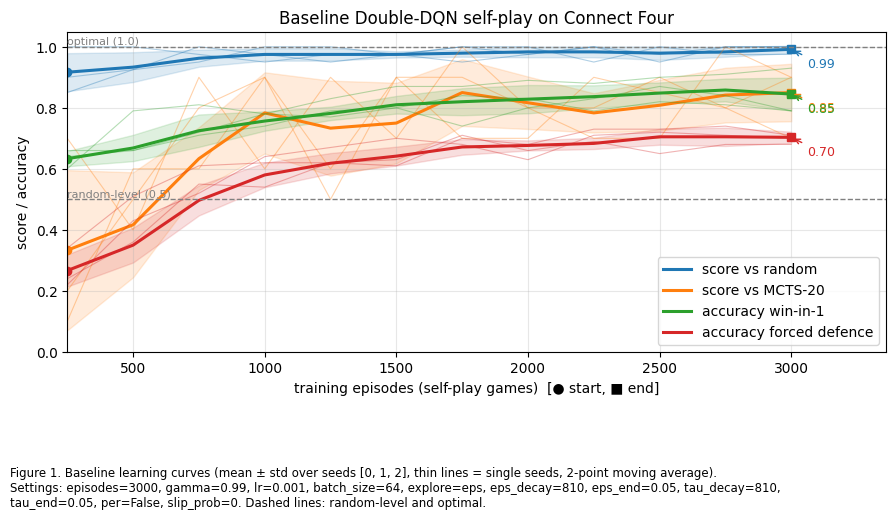

In [23]:
groups = {"score vs random": stack(H_base, "score_random"),
          f"score vs MCTS-{cfg_base.mcts_eval_sims}": stack(H_base, "score_mcts"),
          "accuracy win-in-1": stack(H_base, "tactic_win"),
          "accuracy forced defence": stack(H_base, "tactic_block")}
plot_curves(groups, X, "score / accuracy", "Baseline Double-DQN self-play on Connect Four",
            f"Baseline learning curves (mean ± std over seeds {SEEDS}, thin lines = single seeds, 2-point moving average). "
            f"Settings: {settings_str(cfg_base)}. Dashed lines: random-level and optimal.",
            "baseline", ma=2, hlines=REF, show_seeds=True)

**Training diagnostics.** Two sanity plots: the Huber loss and the exploration schedule ε(t). The loss in RL is *not* expected to decrease monotonically (the targets move as the policy improves), but it should stay bounded. The ε curve shows when the agent switches from mostly exploring to mostly exploiting, which is useful to interpret the learning curve above.

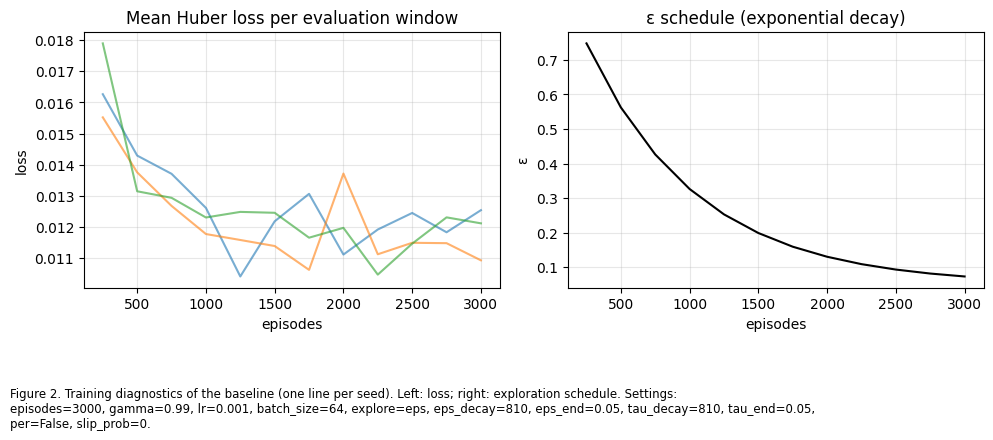

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.4))
for h in H_base: axs[0].plot(X, h["loss"], alpha=.6)
axs[0].set_title("Mean Huber loss per evaluation window"); axs[0].set_xlabel("episodes"); axs[0].set_ylabel("loss"); axs[0].grid(alpha=.3)
axs[1].plot(X, H_base[0]["explore_param"], "k-"); axs[1].set_title("ε schedule (exponential decay)")
axs[1].set_xlabel("episodes"); axs[1].set_ylabel("ε"); axs[1].grid(alpha=.3)
finish_fig(fig, f"Training diagnostics of the baseline (one line per seed). Left: loss; right: exploration schedule. Settings: {settings_str(cfg_base)}.", "diagnostics")

### 6.2 Comparing exploration strategies

Four ways to explore, everything else equal: **ε-greedy with decay** (baseline), **Boltzmann with annealed temperature** (τ 1.0 → 0.05), **fixed ε = 0.1** (never stops exploring), and **no exploration** (ε = 0, pure greedy). Hypothesis: with sparse rewards some exploration is essential, a decaying schedule should end best because late exploitation sharpens play, and Boltzmann should be competitive because it explores *good* moves more than hopeless ones.

In [25]:
H_boltz  = run_experiment("explore_boltz",  replace(BASE, explore="boltz"))
H_fixed  = run_experiment("explore_fixed",  replace(BASE, eps_start=0.1, eps_end=0.1))
H_greedy = run_experiment("explore_greedy", replace(BASE, eps_start=0.0, eps_end=0.0))
EXPL = {"ε-greedy, decay 1→0.05": H_base, "Boltzmann, τ 1→0.05": H_boltz,
        "fixed ε=0.1": H_fixed, "no exploration (ε=0)": H_greedy}

[explore_boltz] seed 0: final score vs random = 1.00 (158s)
[explore_boltz] seed 1: final score vs random = 1.00 (155s)
[explore_boltz] seed 2: final score vs random = 1.00 (160s)
[explore_fixed] seed 0: final score vs random = 0.97 (142s)
[explore_fixed] seed 1: final score vs random = 0.97 (139s)
[explore_fixed] seed 2: final score vs random = 0.97 (140s)
[explore_greedy] seed 0: final score vs random = 0.95 (143s)
[explore_greedy] seed 1: final score vs random = 0.95 (142s)
[explore_greedy] seed 2: final score vs random = 0.97 (142s)


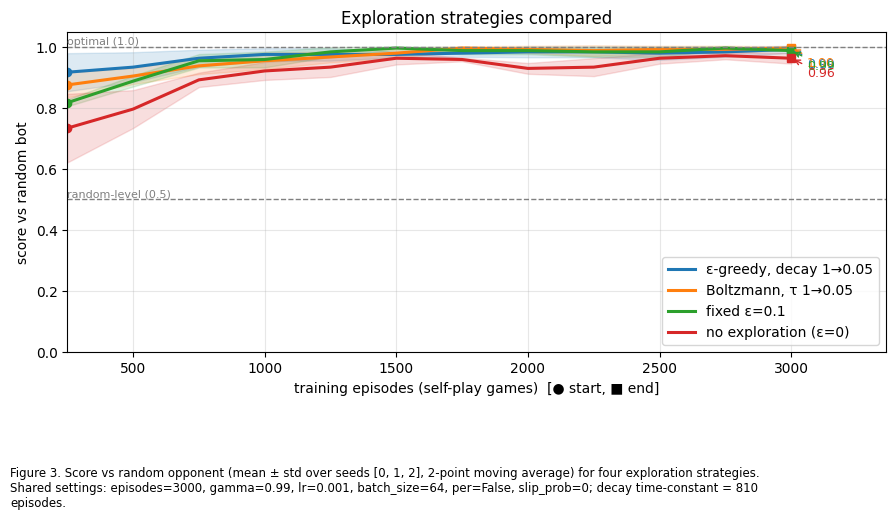

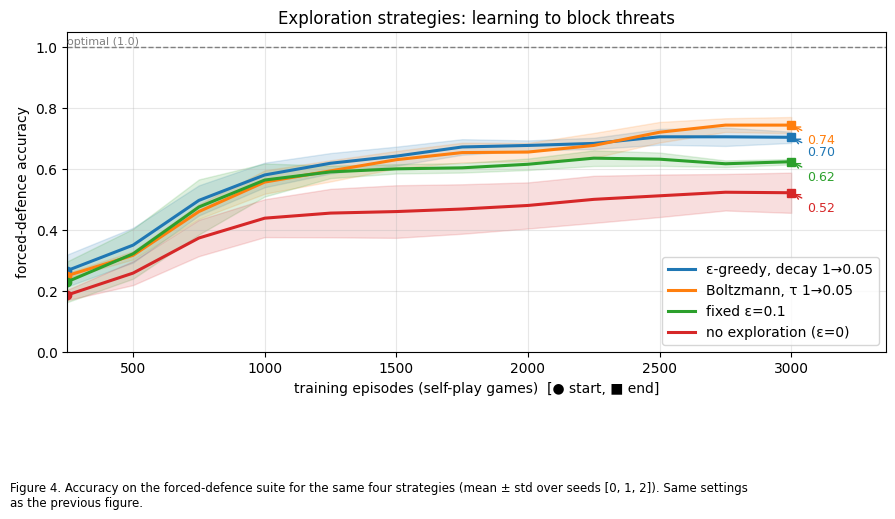

,final_mean,final_std,area_under_curve,volatility
config,,,,
"ε-greedy, decay 1→0.05",0.986,0.004,0.973,0.025
"Boltzmann, τ 1→0.05",0.994,0.004,0.969,0.013
fixed ε=0.1,0.989,0.004,0.967,0.015
no exploration (ε=0),0.967,0.007,0.922,0.030


In [26]:
plot_curves({k: stack(v, "score_random") for k, v in EXPL.items()}, X, "score vs random bot",
            "Exploration strategies compared",
            f"Score vs random opponent (mean ± std over seeds {SEEDS}, 2-point moving average) for four exploration strategies. "
            f"Shared settings: {settings_str(BASE, ['episodes','gamma','lr','batch_size','per','slip_prob'])}; decay time-constant = {BASE.eps_decay:g} episodes.",
            "exploration", ma=2, hlines=REF)
plot_curves({k: stack(v, "tactic_block") for k, v in EXPL.items()}, X, "forced-defence accuracy",
            "Exploration strategies: learning to block threats",
            f"Accuracy on the forced-defence suite for the same four strategies (mean ± std over seeds {SEEDS}). Same settings as the previous figure.",
            "exploration_block", ma=2, hlines=[(1.0, "optimal (1.0)")])
summarize({k: stack(v, "score_random") for k, v in EXPL.items()}, X)

**Why would these differ?** Without exploration the first moves are decided by an untrained network, so the data lacks diverse game endings and the agent may repeat the same few lines of play. A fixed ε keeps injecting random moves, which hurts a *self-play* agent's evaluation of strong lines (the opponent it plays against in training blunders too often). To *confirm* the explanation rather than just assert it, look at the forced-defence plot: if a method scores poorly on score vs random but also on blocking, the cause is missing tactical knowledge rather than noise in the evaluation. A natural follow-up would be to measure state coverage (number of distinct positions visited) per strategy.

### 6.3 Stability: how fast to decay ε, how cold to make τ

Here we study the **ε–τ trade-off** (when is the algorithm stable). Sweep (a): the ε decay time-constant – *fast* (5 % of training), *base* (27 %), *slow* (67 %). Sweep (b): the final temperature τ_end ∈ {0.02, 0.05, 0.5}. Too fast a decay means the agent exploits a half-trained network; too slow means it learns from noisy play and is still "mostly random" at the end. A final τ that is too high keeps the policy near-uniform (Q-differences are at most 2, so τ = 0.5 still gives weak preference), while a very low τ is almost greedy. We look at final score, area under the curve and **volatility** (average change between consecutive evaluations in the second half of training – our stability measure).

In [27]:
E = EPISODES
H_fast = run_experiment("eps_fast", replace(BASE, eps_decay=0.05 * E))
H_slow = run_experiment("eps_slow", replace(BASE, eps_decay=0.67 * E))
SWEEP_EPS = {f"ε decay fast ({0.05*E:g} ep)": H_fast, f"ε decay base ({BASE.eps_decay:g} ep)": H_base,
             f"ε decay slow ({0.67*E:g} ep)": H_slow}

H_t_hot  = run_experiment("tau_hot",  replace(BASE, explore="boltz", tau_end=0.5))
H_t_cold = run_experiment("tau_cold", replace(BASE, explore="boltz", tau_end=0.02))
SWEEP_TAU = {"τ_end = 0.02": H_t_cold, "τ_end = 0.05": H_boltz, "τ_end = 0.5": H_t_hot}

[eps_fast] seed 0: final score vs random = 1.00 (150s)
[eps_fast] seed 1: final score vs random = 1.00 (149s)
[eps_fast] seed 2: final score vs random = 1.00 (155s)
[eps_slow] seed 0: final score vs random = 1.00 (115s)
[eps_slow] seed 1: final score vs random = 1.00 (119s)
[eps_slow] seed 2: final score vs random = 0.97 (118s)
[tau_hot] seed 0: final score vs random = 1.00 (164s)
[tau_hot] seed 1: final score vs random = 1.00 (161s)
[tau_hot] seed 2: final score vs random = 1.00 (162s)
[tau_cold] seed 0: final score vs random = 1.00 (155s)
[tau_cold] seed 1: final score vs random = 1.00 (164s)
[tau_cold] seed 2: final score vs random = 1.00 (162s)


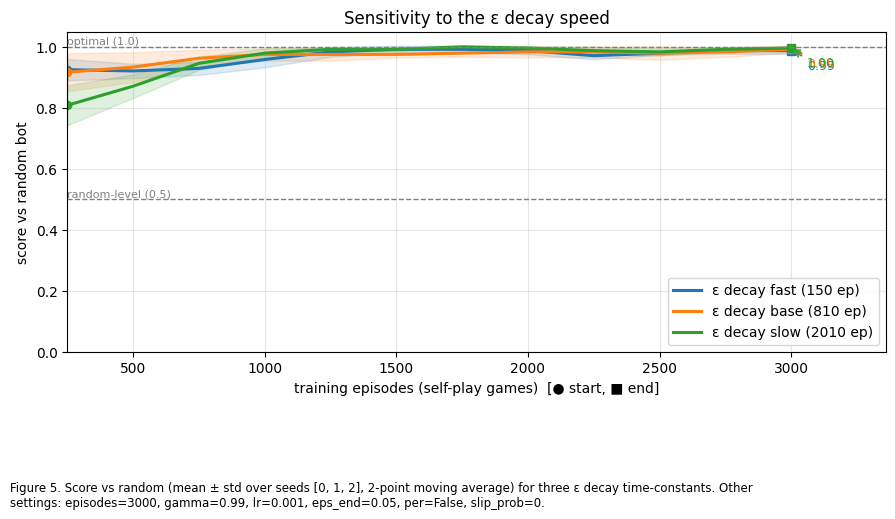

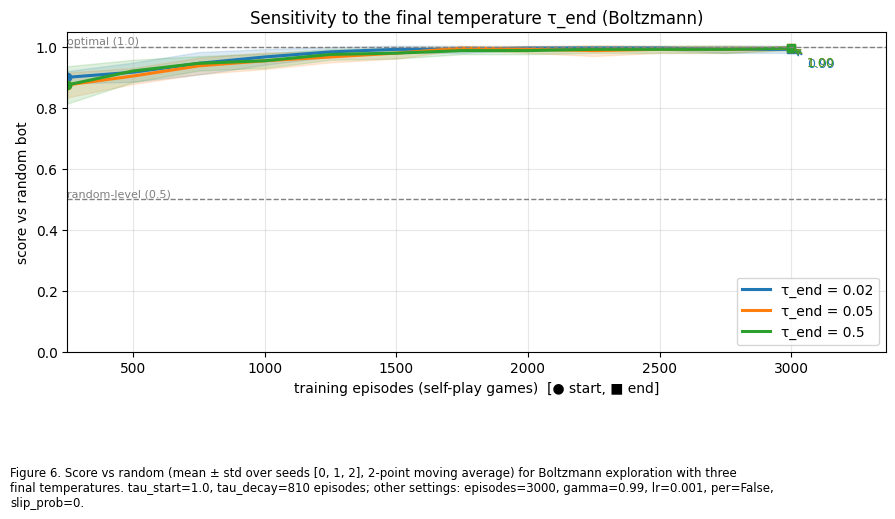

ε-decay sweep


,final_mean,final_std,area_under_curve,volatility
config,,,,
ε decay fast (150 ep),0.992,0.007,0.971,0.028
ε decay base (810 ep),0.986,0.004,0.973,0.025
ε decay slow (2010 ep),0.992,0.007,0.969,0.012


τ_end sweep


,final_mean,final_std,area_under_curve,volatility
config,,,,
τ_end = 0.02,0.994,0.008,0.976,0.012
τ_end = 0.05,0.994,0.004,0.969,0.013
τ_end = 0.5,0.994,0.004,0.972,0.010


In [28]:
plot_curves({k: stack(v, "score_random") for k, v in SWEEP_EPS.items()}, X, "score vs random bot",
            "Sensitivity to the ε decay speed",
            f"Score vs random (mean ± std over seeds {SEEDS}, 2-point moving average) for three ε decay time-constants. "
            f"Other settings: {settings_str(BASE, ['episodes','gamma','lr','eps_end','per','slip_prob'])}.",
            "eps_sweep", ma=2, hlines=REF)
plot_curves({k: stack(v, "score_random") for k, v in SWEEP_TAU.items()}, X, "score vs random bot",
            "Sensitivity to the final temperature τ_end (Boltzmann)",
            f"Score vs random (mean ± std over seeds {SEEDS}, 2-point moving average) for Boltzmann exploration with three final temperatures. "
            f"tau_start=1.0, tau_decay={BASE.tau_decay:g} episodes; other settings: {settings_str(BASE, ['episodes','gamma','lr','per','slip_prob'])}.",
            "tau_sweep", ma=2, hlines=REF)
print("ε-decay sweep"); display(summarize({k: stack(v, "score_random") for k, v in SWEEP_EPS.items()}, X))
print("τ_end sweep");   display(summarize({k: stack(v, "score_random") for k, v in SWEEP_TAU.items()}, X))

### 6.4 Prioritized Experience Replay

Same baseline, but replay transitions with probability ∝ |TD-error|^0.6 (importance-sampling correction β: 0.4 → 1). Hypothesis: in a sparse-reward game, the transitions that end the game (or lead to forced wins/losses) carry the most information, so PER should speed up the learning of tactics such as win-in-1 and forced defence, possibly at the price of higher variance. We compare uniform vs prioritized on both the tactical accuracy and the score vs random.

[per] seed 0: final score vs random = 0.95 (138s)
[per] seed 1: final score vs random = 1.00 (143s)
[per] seed 2: final score vs random = 0.95 (136s)


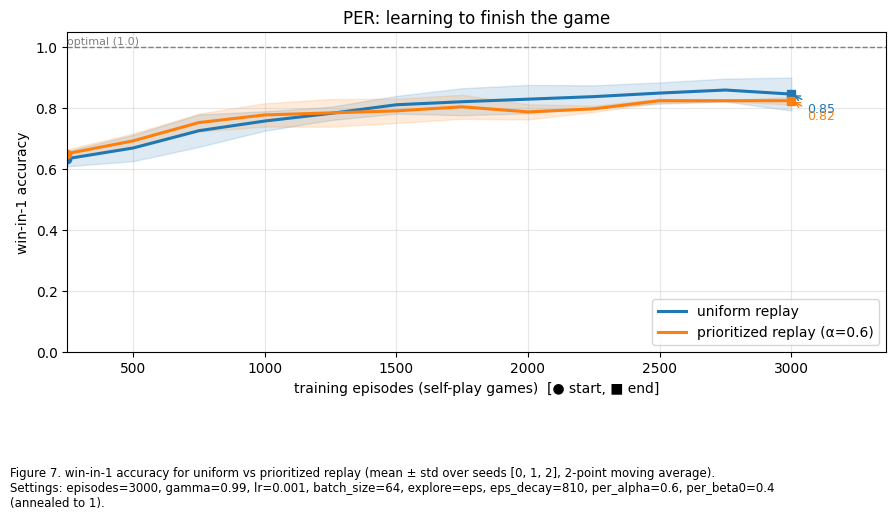

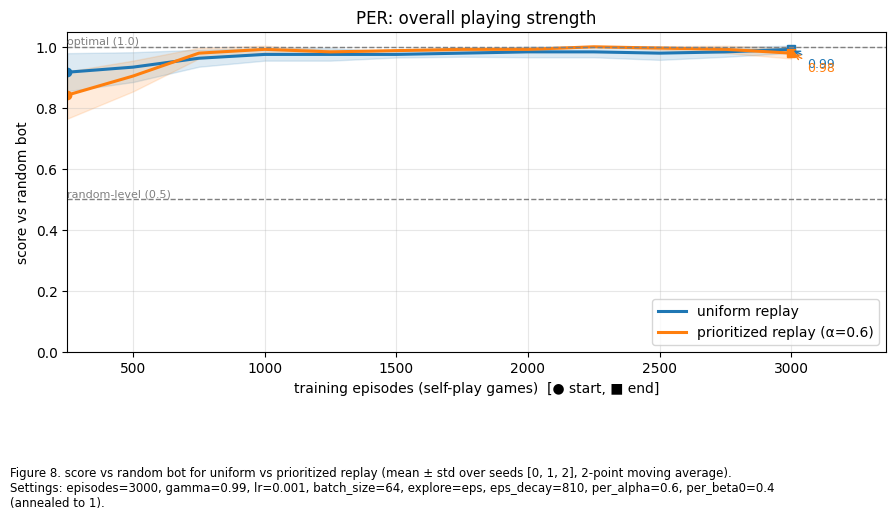

,final_mean,final_std,area_under_curve,volatility
config,,,,
uniform replay,0.851,0.045,0.793,0.027
prioritized replay (α=0.6),0.821,0.007,0.782,0.033


In [29]:
H_per = run_experiment("per", replace(BASE, per=True))
PER = {"uniform replay": H_base, "prioritized replay (α=0.6)": H_per}
for metric, ylab, fn, ttl in [("tactic_win", "win-in-1 accuracy", "per_win", "PER: learning to finish the game"),
                              ("score_random", "score vs random bot", "per_score", "PER: overall playing strength")]:
    plot_curves({k: stack(v, metric) for k, v in PER.items()}, X, ylab, ttl,
                f"{ylab} for uniform vs prioritized replay (mean ± std over seeds {SEEDS}, 2-point moving average). "
                f"Settings: {settings_str(BASE, ['episodes','gamma','lr','batch_size','explore','eps_decay'])}, per_alpha=0.6, per_beta0=0.4 (annealed to 1).",
                fn, ma=2, hlines=REF if metric == "score_random" else [(1.0, "optimal (1.0)")])
summarize({k: stack(v, "tactic_win") for k, v in PER.items()}, X)

### 6.5 Deterministic vs stochastic environment

Connect Four is deterministic, so we *inject* stochasticity: with probability `slip_prob` the chosen column is replaced by a random legal one (a "slippery" move), both during self-play and in the stored transitions. Evaluation still uses the normal deterministic game. We test slip = 0, 0.1 and 0.25. The agent now learns the *expected* value of an action under noise, which blurs the value of precise tactics; but the noise also forces extra exploration of unusual positions.

[slip10] seed 0: final score vs random = 1.00 (131s)
[slip10] seed 1: final score vs random = 1.00 (131s)
[slip10] seed 2: final score vs random = 1.00 (134s)
[slip25] seed 0: final score vs random = 1.00 (132s)
[slip25] seed 1: final score vs random = 1.00 (129s)
[slip25] seed 2: final score vs random = 1.00 (133s)


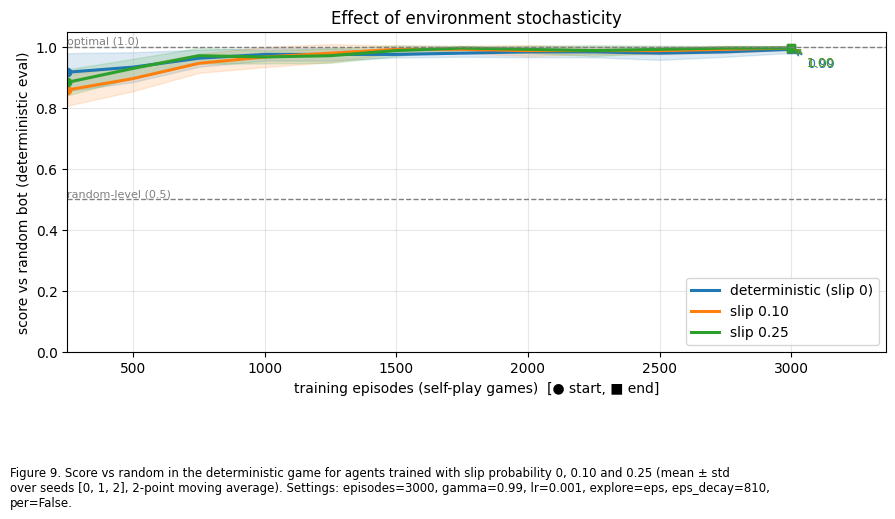

,final_mean,final_std,area_under_curve,volatility
config,,,,
deterministic (slip 0),0.986,0.004,0.973,0.025
slip 0.10,0.994,0.004,0.971,0.013
slip 0.25,0.997,0.004,0.977,0.015


In [30]:
H_s10 = run_experiment("slip10", replace(BASE, slip_prob=0.10))
H_s25 = run_experiment("slip25", replace(BASE, slip_prob=0.25))
STOCH = {"deterministic (slip 0)": H_base, "slip 0.10": H_s10, "slip 0.25": H_s25}
plot_curves({k: stack(v, "score_random") for k, v in STOCH.items()}, X, "score vs random bot (deterministic eval)",
            "Effect of environment stochasticity",
            f"Score vs random in the deterministic game for agents trained with slip probability 0, 0.10 and 0.25 (mean ± std over seeds {SEEDS}, "
            f"2-point moving average). Settings: {settings_str(BASE, ['episodes','gamma','lr','explore','eps_decay','per'])}.",
            "stochastic", ma=2, hlines=REF)
summarize({k: stack(v, "score_random") for k, v in STOCH.items()}, X)

### 6.6 Seeding: reproducibility and run-to-run variance

Two checks. (1) **Reproducibility:** training twice with the same seed must give *identical* histories, otherwise no comparison in this notebook is trustworthy. On a GPU this needs the deterministic kernels set in `set_seed` (some convolution and `gather` backward kernels are non-deterministic by default, which made this check fail in our first version). (2) **Variance:** the spread between seeds (thin lines in the baseline figure) tells us how large a difference must be before we call one method better; with only a few seeds, differences smaller than the seed-to-seed std are not significant.

In [31]:
cfg_t = replace(BASE, episodes=60, warmup=200, eval_every=30, eval_games=10)
_, h1 = train(cfg_t, seed=123)
_, h2 = train(cfg_t, seed=123)
_, h3 = train(cfg_t, seed=124)
print("same seed twice  -> identical history:", np.allclose(h1["score_random"], h2["score_random"]) and np.allclose(h1["loss"], h2["loss"]))
print("different seed   -> identical history:", np.allclose(h1["loss"], h3["loss"]))
final = {k: np.nanmean(stack(v, "score_random")[:, -3:], axis=1) for k, v in {"baseline": H_base}.items()}
print("Baseline final score per seed:", np.round(final["baseline"], 3), "| std across seeds: %.3f" % final["baseline"].std())

same seed twice  -> identical history: True
different seed   -> identical history: False
Baseline final score per seed: [0.983 0.992 0.983] | std across seeds: 0.004


## 7. Understanding the agent's decisions

### 7.1 Q-values with arrows

Numbers on a curve don't show *why* the agent wins. Here we load a trained baseline agent and show, for three positions, the board and its **Q-value for each column** (grey = illegal). The **green arrow** marks the objectively correct move(s) and the **blue arrow** the move the agent picks; when they coincide the agent "gets it". The positions are the empty board (known result: the first player wins by opening in the centre column – Allis, 1988), a *win-in-1* position and a *forced defence* position. The sign of the Q-value is meaningful: close to +1 = "I expect to win", close to −1 = "I expect to lose".

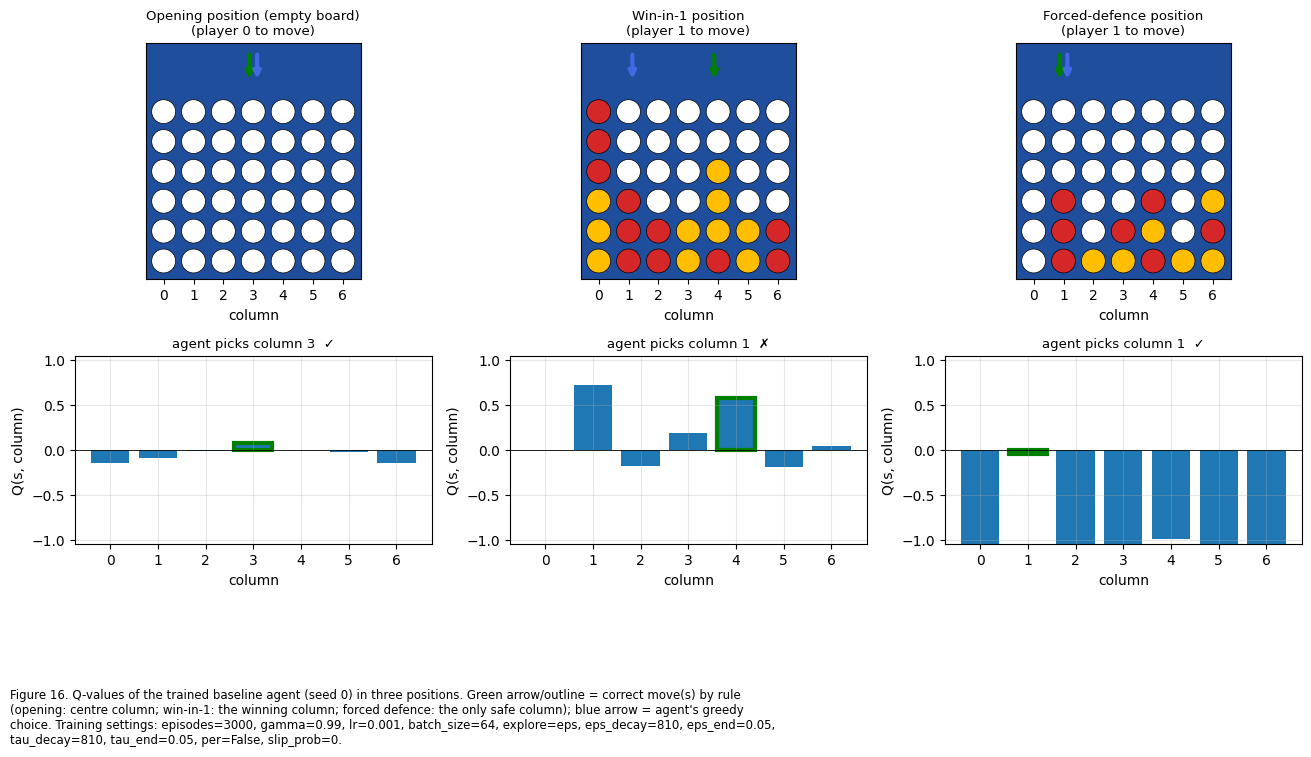

In [46]:
def parse_board(state):
    rows = [l.strip() for l in str(state).splitlines() if len(l.strip()) == 7 and set(l.strip()) <= set(".xo")]
    assert len(rows) == 6, "unexpected board string format"
    return rows

def draw_board(ax, state, title=""):
    colors = {".": "white", "x": "#d62728", "o": "#ffbf00"}
    ax.set_facecolor("#1f4e9c")
    for i, row in enumerate(parse_board(state)):
        for x, ch in enumerate(row):
            ax.add_patch(plt.Circle((x, 5 - i), 0.4, fc=colors[ch], ec="k", lw=0.5))
    ax.set_xlim(-0.6, 6.6); ax.set_ylim(-0.6, 7.3); ax.set_aspect("equal")
    ax.set_xticks(range(7)); ax.set_yticks([]); ax.set_xlabel("column"); ax.set_title(title, fontsize=9.5)

def show_decisions(agent, items, caption, fname):
    n = len(items)
    fig, axs = plt.subplots(2, n, figsize=(4.4 * n, 7.6), gridspec_kw=dict(height_ratios=[1.25, 1]))
    axs = np.atleast_2d(axs).reshape(2, n)
    for j, (label, s, optimal) in enumerate(items):
        q = agent.q_values(encode(s)); legal = s.legal_actions()
        pick = agent.greedy_action(encode(s), legal)
        draw_board(axs[0, j], s, f"{label}\n(player {s.current_player()} to move)")
        for a in optimal:
            axs[0, j].annotate("", xy=(a - 0.13, 6.0), xytext=(a - 0.13, 7.0), arrowprops=dict(arrowstyle="-|>", color="green", lw=3))
        axs[0, j].annotate("", xy=(pick + 0.13, 6.0), xytext=(pick + 0.13, 7.0), arrowprops=dict(arrowstyle="-|>", color="royalblue", lw=3))
        vals = np.where(legal_mask(s), q, 0.0)
        bars = axs[1, j].bar(range(7), vals, color=["tab:blue" if legal_mask(s)[c] else "lightgray" for c in range(7)])
        for a in optimal: bars[a].set_edgecolor("green"); bars[a].set_linewidth(3)
        axs[1, j].axhline(0, color="k", lw=0.6); axs[1, j].set_ylim(-1.05, 1.05)
        axs[1, j].set_xlabel("column"); axs[1, j].set_ylabel("Q(s, column)"); axs[1, j].grid(alpha=0.3)
        axs[1, j].set_title("agent picks column %d  %s" % (pick, "✓" if pick in optimal else "✗"), fontsize=9.5)
    finish_fig(fig, caption, fname)

agent0 = load_agent("baseline", SEEDS[0])
items = [("Opening position (empty board)", game.new_initial_state(), [3]),
         ("Win-in-1 position", TACT["win"]["items"][0][0], TACT["win"]["items"][0][1]),
         ("Forced-defence position", TACT["block"]["items"][0][0], TACT["block"]["items"][0][1])]
show_decisions(agent0, items,
               f"Q-values of the trained baseline agent (seed {SEEDS[0]}) in three positions. Green arrow/outline = correct move(s) by rule "
               f"(opening: centre column; win-in-1: the winning column; forced defence: the only safe column); blue arrow = agent's greedy choice. "
               f"Training settings: {settings_str(cfg_base)}.", "qvalues")

**Following up on the explanation.** If the agent really learned *tactics* (and did not just get lucky) it should (i) choose the correct move in most of the 100 win-in-1 and 100 forced-defence positions, and (ii) value the centre column highest on the empty board. The next cell measures (i) for every trained agent of the baseline and also prints how often the agent picks each opening column, which is a direct test of (ii).

In [33]:
rows = []
for sd in SEEDS:
    a = load_agent("baseline", sd)
    acc = tactic_accuracy(a)
    q0 = a.q_values(encode(game.new_initial_state()))
    rows.append(dict(seed=sd, win_in_1=acc["win"], forced_defence=acc["block"], best_opening_col=int(np.argmax(q0)),
                     **{f"Q(col{c})": round(float(q0[c]), 2) for c in range(7)}))
display(pd.DataFrame(rows).set_index("seed"))

,win_in_1,forced_defence,best_opening_col,Q(col0),Q(col1),Q(col2),Q(col3),Q(col4),Q(col5),Q(col6)
seed,,,,,,,,,,
0,0.79,0.68,3,-0.14,-0.09,-0.01,0.08,0.00,-0.02,-0.14
1,0.93,0.70,2,-0.16,-0.07,0.05,-0.08,-0.07,-0.02,-0.10
2,0.79,0.71,3,-0.05,0.01,0.04,0.10,0.03,-0.05,-0.07


### 7.2 Playing strength against MCTS of increasing strength

Finally, we test how strong the trained agent (baseline, first seed) really is by playing it against MCTS opponents with 10, 50 and 200 simulations per move, alternating colours. This is the most honest strength measure: unlike the random bot, MCTS punishes tactical mistakes. Increase `N_FINAL` for tighter estimates (this cell can be slow because MCTS runs in Python).

,win,draw,loss,score
opponent,,,,
random,97,0,3,0.970000
MCTS-10,26,0,4,0.866667
MCTS-50,11,0,19,0.366667
MCTS-200,4,0,26,0.133333


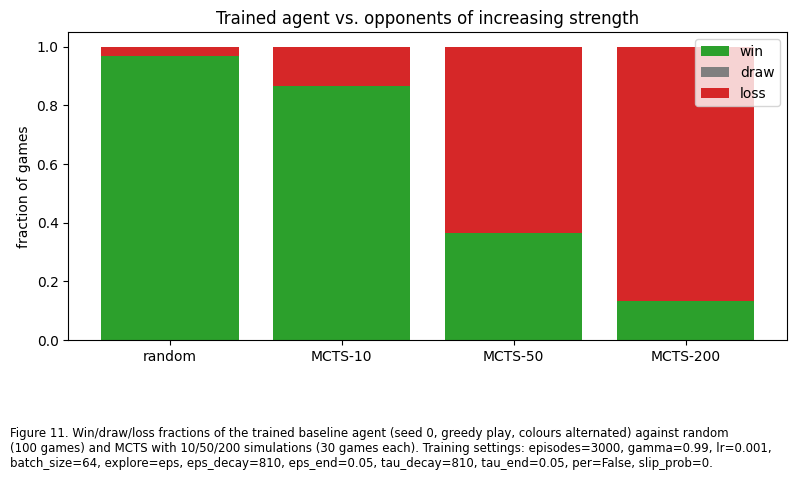

In [34]:
N_FINAL = 10 if QUICK else 30
sims_list = [10, 50, 200]
rows = []
for sims in sims_list:
    r = evaluate(agent0.bot(), make_mcts_bot(sims, 777), N_FINAL)
    rows.append(dict(opponent=f"MCTS-{sims}", **r))
r = evaluate(agent0.bot(), make_random_bot(778), 100)
rows.insert(0, dict(opponent="random", **r))
df_final = pd.DataFrame(rows).set_index("opponent")
display(df_final)

fig, ax = plt.subplots(figsize=(8, 4.8))
tot = df_final[["win", "draw", "loss"]].sum(axis=1)
bottom = np.zeros(len(df_final))
for col, c in [("win", "tab:green"), ("draw", "tab:gray"), ("loss", "tab:red")]:
    v = (df_final[col] / tot).values
    ax.bar(df_final.index, v, bottom=bottom, color=c, label=col); bottom += v
ax.set_ylabel("fraction of games"); ax.set_title("Trained agent vs. opponents of increasing strength"); ax.legend()
finish_fig(fig, f"Win/draw/loss fractions of the trained baseline agent (seed {SEEDS[0]}, greedy play, colours alternated) against random (100 games) "
                f"and MCTS with 10/50/200 simulations ({N_FINAL} games each). Training settings: {settings_str(cfg_base)}.", "final_eval")

### 7.3 A sample game

To make start and end states explicit we let the trained agent play one game against MCTS-50 and show snapshots: the **start** (empty board), two intermediate positions and the **end** state with the result. This is a qualitative check of whether the moves look sensible (centre control, blocking threats, building double threats).

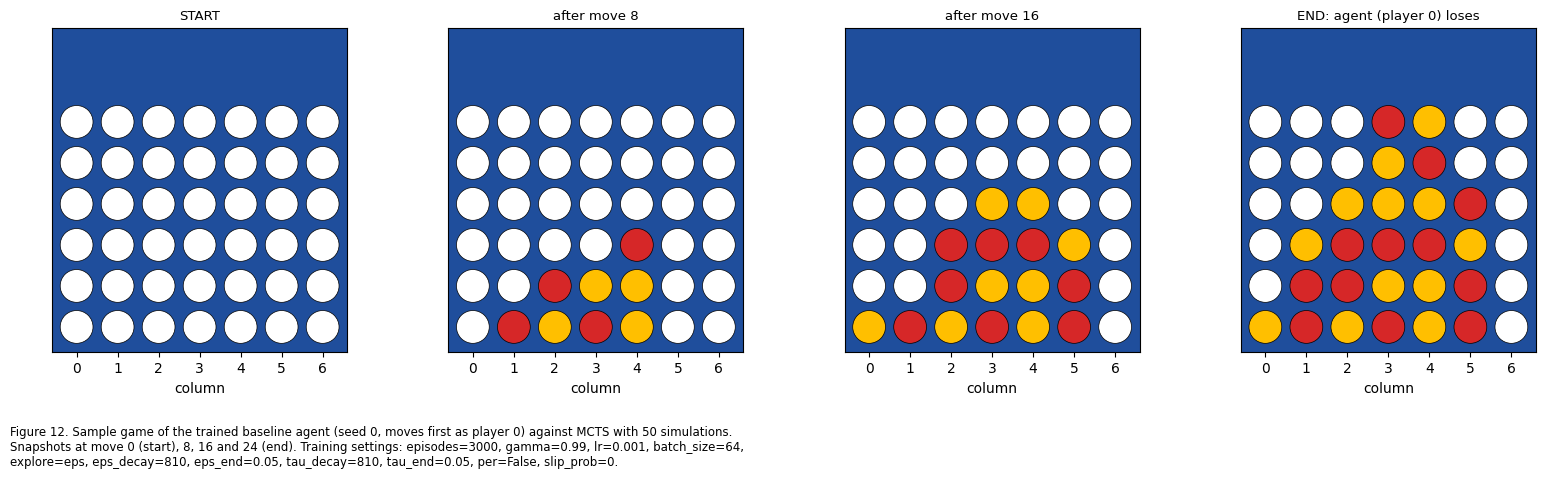

In [35]:
def play_and_record(agent_bot, opp_bot, agent_first=True):
    s = game.new_initial_state(); states = [s.clone()]
    while not s.is_terminal():
        agent_turn = (s.current_player() == 0) == agent_first
        s.apply_action(agent_bot(s) if agent_turn else opp_bot(s)); states.append(s.clone())
    return states

states = play_and_record(agent0.bot(), make_mcts_bot(50, 99), agent_first=True)
n = len(states) - 1
idxs = [0, n // 3, 2 * n // 3, n]
res = states[-1].returns()[0]
outcome = "agent (player 0) WINS" if res > 0 else ("agent (player 0) loses" if res < 0 else "draw")
fig, axs = plt.subplots(1, 4, figsize=(16, 4.6))
for ax, i, name in zip(axs, idxs, ["START", f"after move {idxs[1]}", f"after move {idxs[2]}", f"END: {outcome}"]):
    draw_board(ax, states[i], name)
finish_fig(fig, f"Sample game of the trained baseline agent (seed {SEEDS[0]}, moves first as player 0) against MCTS with 50 simulations. "
                f"Snapshots at move 0 (start), {idxs[1]}, {idxs[2]} and {n} (end). Training settings: {settings_str(cfg_base)}.", "sample_game")

## 8. Save results for the report and slides

All figures are already in `figures/` (numbered, with captions). This cell also exports a compact CSV with the final metrics of every experiment so you can paste exact numbers in the report and use them in the three-slide presentation.

In [36]:
ALL = {"baseline": H_base, "boltzmann": H_boltz, "fixed eps 0.1": H_fixed, "greedy (no explore)": H_greedy,
       "eps decay fast": H_fast, "eps decay slow": H_slow, "tau_end 0.5": H_t_hot, "tau_end 0.02": H_t_cold,
       "PER": H_per, "slip 0.10": H_s10, "slip 0.25": H_s25}
rows = []
for k, v in ALL.items():
    for m in ["score_random", "tactic_win", "tactic_block"]:
        f = np.nanmean(stack(v, m)[:, -3:], axis=1)
        rows.append(dict(experiment=k, metric=m, final_mean=f.mean(), final_std=f.std()))
df_all = pd.DataFrame(rows).round(3)
df_all.to_csv("results/summary.csv", index=False)
display(df_all.pivot(index="experiment", columns="metric", values="final_mean"))

metric,score_random,tactic_block,tactic_win
experiment,,,
PER,0.983,0.683,0.821
baseline,0.986,0.702,0.851
boltzmann,0.994,0.742,0.834
eps decay fast,0.992,0.649,0.844
eps decay slow,0.992,0.746,0.859
fixed eps 0.1,0.989,0.624,0.852
greedy (no explore),0.967,0.520,0.768
slip 0.10,0.994,0.660,0.810
slip 0.25,0.997,0.716,0.824


## 9. Extension: a stronger agent

Section 7.2 shows the limit of the baseline: it beats random and MCTS-10, but loses about half of its games to MCTS-50 and nearly all to MCTS-200. We combine three changes, each aimed at a weakness we observed:
1. **More capacity** – a deeper residual network with a dueling head (9.1).
2. **More and better data** – left-right mirror augmentation and ~7× more self-play games (9.2).
3. **Look-ahead at play time** – a shallow negamax search that lets the network judge positions a few moves ahead (9.3).

(1) and (2) change training, (3) only changes how the trained network is used, so we can measure their effects separately (9.4).

### 9.1 Residual dueling Q-network

A 3×3 stem convolution followed by 4 **residual blocks** (two 3×3 convs plus a skip connection, He et al. 2016). Nine stacked 3×3 convs see the whole 6×7 board, so the network can relate distant discs such as both ends of a diagonal, and the skip connections keep this deeper network easy to train. The **dueling head** (Wang et al. 2016) splits the output into a state value V(s) and per-column advantages A(s, a), with Q = V + A − mean(A). In Connect Four many positions are won or lost whatever column is played; the dueling head learns that shared value once instead of separately for each of the 7 outputs. Registering the class in `NETS` is all `Config(net="resnet")` needs.

In [37]:
class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.c1 = nn.Conv2d(ch, ch, 3, padding=1)
        self.c2 = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x):
        return F.relu(x + self.c2(F.relu(self.c1(x))))

class DuelResQNet(nn.Module):
    def __init__(self, ch=64, blocks=4, hidden=256):
        super().__init__()
        self.stem = nn.Conv2d(3, ch, 3, padding=1)
        self.blocks = nn.Sequential(*[ResBlock(ch) for _ in range(blocks)])
        self.fc = nn.Linear(ch * 6 * 7, hidden)
        self.value = nn.Linear(hidden, 1)
        self.adv = nn.Linear(hidden, 7)

    def forward(self, x):
        h = F.relu(self.fc(self.blocks(F.relu(self.stem(x))).flatten(1)))
        a = self.adv(h)
        return self.value(h) + a - a.mean(1, keepdim=True)

NETS["resnet"] = DuelResQNet
print("Parameters:", sum(p.numel() for p in DuelResQNet().parameters()), "| baseline QNet:", sum(p.numel() for p in QNet().parameters()))

Parameters: 987656 | baseline QNet: 420743


### 9.2 Training the strong agent

Connect Four is **left-right symmetric**: mirroring a position mirrors its best move (column c ↔ 6 − c). With `mirror=True` the training loop stores every transition twice, as played and mirrored. That doubles the data for free and teaches the network a property it would otherwise have to discover on its own. We also train ~7× longer and adapt the hyper-parameters to the larger network: a lower learning rate (5e-4), a bigger replay buffer and batch, and a slower target sync (every 2 000 steps) for more stable targets. The ε schedule keeps the same *shape* relative to the run length. We train a single seed (~20 min on a Colab T4). During training we track the score vs MCTS-50, because the random bot is no longer a useful opponent.

[strong] seed 0: final score vs random = 1.00 (2338s)


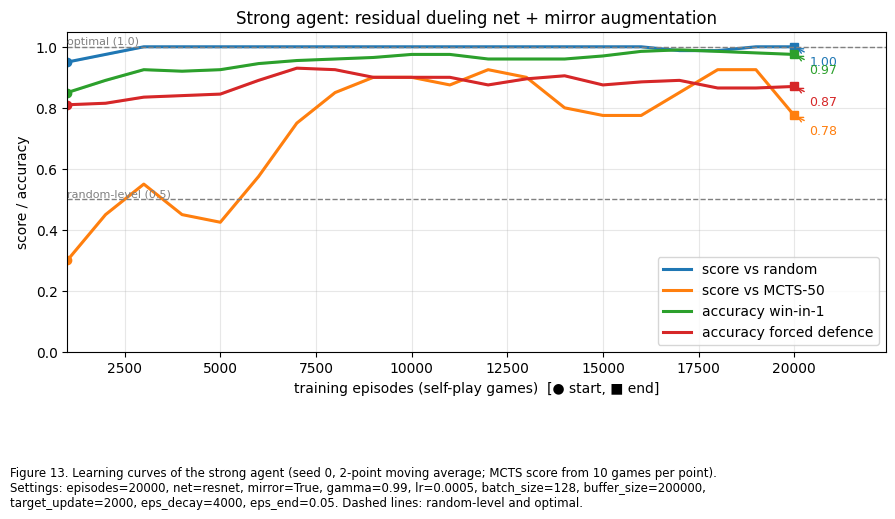

In [38]:
EPISODES_STRONG = 1000 if QUICK else 20_000
cfg_strong = replace(BASE, episodes=EPISODES_STRONG, net="resnet", mirror=True, lr=5e-4, buffer_size=200_000, batch_size=128,
                     warmup=500 if QUICK else 5_000, target_update=2_000, eps_decay=0.2 * EPISODES_STRONG,
                     eval_every=EPISODES_STRONG // 20, mcts_eval_games=4 if QUICK else 10, mcts_eval_sims=50)
STRONG_KEYS = ["episodes", "net", "mirror", "gamma", "lr", "batch_size", "buffer_size", "target_update", "eps_decay", "eps_end"]
H_strong = run_experiment("strong", cfg_strong, seeds=[0])
X_strong = np.array(H_strong[0]["episode"])

plot_curves({"score vs random": stack(H_strong, "score_random"),
             f"score vs MCTS-{cfg_strong.mcts_eval_sims}": stack(H_strong, "score_mcts"),
             "accuracy win-in-1": stack(H_strong, "tactic_win"),
             "accuracy forced defence": stack(H_strong, "tactic_block")},
            X_strong, "score / accuracy", "Strong agent: residual dueling net + mirror augmentation",
            f"Learning curves of the strong agent (seed 0, 2-point moving average; MCTS score from {cfg_strong.mcts_eval_games} games per point). "
            f"Settings: {settings_str(cfg_strong, STRONG_KEYS)}. Dashed lines: random-level and optimal.",
            "strong", ma=2, hlines=REF)

### 9.3 Look-ahead search at play time

A Q-network rates every column in one shot, so one misjudged position can decide the game. MCTS is strong because it *checks* moves by looking ahead, and we add the same idea cheaply: a depth-limited **negamax** search over the real game tree. Wins and losses found inside the tree are exact (±1). Positions at the search horizon are scored by the network, V(s) = max over legal a of Q(s, a) (clipped to [−1, 1]), in one batched forward pass per node. As in the training target, the opponent's value is negated and discounted by γ, which also makes the agent prefer quick wins and slow losses. Ties are broken by the raw Q-value. Depth 0 is the plain greedy network; depth 2 can no longer miss a win-in-1 or a forced block, which the check below confirms.

In [39]:
@torch.no_grad()
def state_values(agent, states):
    # V(s) = max over legal Q(s, a), from the view of the player to move in s (one batched forward pass)
    q = agent.q(torch.as_tensor(np.stack([encode(s) for s in states]), device=device)).cpu().numpy()
    q[~np.stack([legal_mask(s) for s in states])] = -np.inf
    return np.clip(q.max(1), -1, 1)

def move_scores(agent, s, depth):
    # negamax look-ahead: score of every column for the player to move (-inf = illegal)
    p, sc, open_ = s.current_player(), np.full(7, -np.inf), []
    for a in s.legal_actions():
        c = s.child(a)
        if c.is_terminal():
            sc[a] = c.returns()[p]
            if sc[a] > 0: return sc                                # immediate win: no need to search further
        else: open_.append((a, c))
    if not open_: return sc
    g = agent.cfg.gamma
    if depth <= 1: vals = -g * state_values(agent, [c for _, c in open_])
    else:          vals = [-g * move_scores(agent, c, depth - 1).max() for _, c in open_]
    for (a, _), v in zip(open_, vals): sc[a] = v
    return sc

def make_search_bot(agent, depth):
    def bot(s):
        q, legal = agent.q_values(encode(s)), s.legal_actions()
        sc = np.full(7, -np.inf); sc[legal] = q[legal]
        if depth > 0: sc = move_scores(agent, s, depth)
        best = np.flatnonzero(sc >= sc.max() - 1e-9)
        return int(best[np.argmax(q[best])])
    return bot

agent_strong = load_agent("strong", 0)
for d in [0, 1, 2, 4]:
    bot, t0 = make_search_bot(agent_strong, d), time.time()
    acc = {name: np.mean([bot(s) in acts for s, acts in T["items"]]) for name, T in TACT.items()}
    print(f"depth {d}: win-in-1 {acc['win']:.2f} | forced defence {acc['block']:.2f} | {1000 * (time.time() - t0) / 200:.0f} ms/move")

depth 0: win-in-1 0.97 | forced defence 0.86 | 3 ms/move
depth 1: win-in-1 1.00 | forced defence 0.97 | 4 ms/move
depth 2: win-in-1 1.00 | forced defence 1.00 | 4 ms/move
depth 4: win-in-1 1.00 | forced defence 1.00 | 33 ms/move


### 9.4 How much stronger?

The honest test from section 7.2 again: every player meets MCTS with 10, 50 and 200 simulations, with colours alternated and the same MCTS seed. *Baseline greedy → strong greedy* isolates the effect of training (9.1 + 9.2), and *strong greedy → strong + search* isolates the look-ahead (9.3). This cell is the slowest of the section, because MCTS runs in Python.

opponent,MCTS-10,MCTS-50,MCTS-200
player,,,
baseline (greedy),0.866667,0.366667,0.133333
strong (greedy),1.000000,0.750000,0.633333
strong + search depth 2,1.000000,0.933333,0.866667
strong + search depth 4,1.000000,1.000000,0.900000


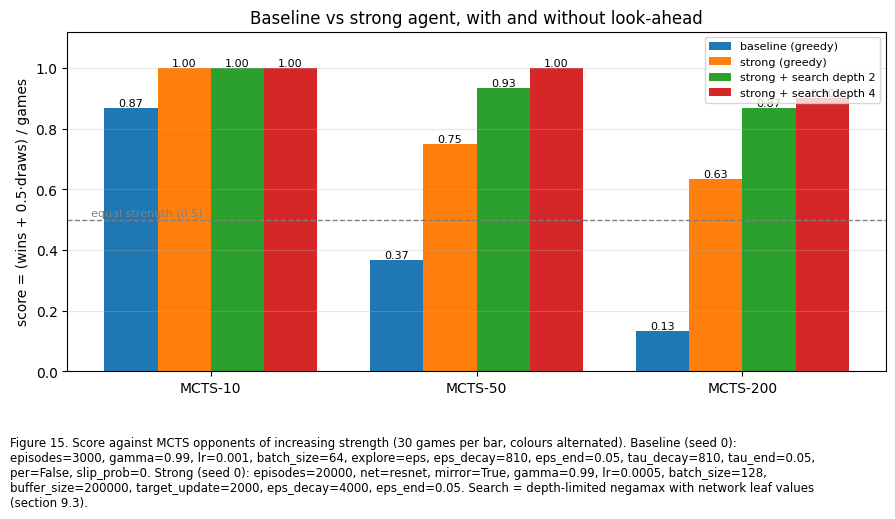

In [44]:
PLAYERS = {"baseline (greedy)": agent0.bot(), "strong (greedy)": make_search_bot(agent_strong, 0),
           "strong + search depth 2": make_search_bot(agent_strong, 2), "strong + search depth 4": make_search_bot(agent_strong, 4)}
rows = []
for name, bot in PLAYERS.items():
    for sims in sims_list:
        rows.append(dict(player=name, opponent=f"MCTS-{sims}", **evaluate(bot, make_mcts_bot(sims, 777), N_FINAL)))
df_strength = pd.DataFrame(rows)
display(df_strength.pivot(index="player", columns="opponent", values="score").loc[list(PLAYERS), [f"MCTS-{s}" for s in sims_list]])

fig, ax = plt.subplots(figsize=(9, 5.2))
w = 0.8 / len(PLAYERS)
for i, name in enumerate(PLAYERS):
    bars = ax.bar(np.arange(len(sims_list)) + (i - (len(PLAYERS) - 1) / 2) * w,
                  df_strength[df_strength.player == name]["score"].values, w, label=name)
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.axhline(0.5, ls="--", color="gray", lw=1); ax.text(-0.45, 0.51, "equal strength (0.5)", color="gray", fontsize=8)
ax.set_xticks(range(len(sims_list))); ax.set_xticklabels([f"MCTS-{s}" for s in sims_list])
ax.set_ylabel("score = (wins + 0.5·draws) / games"); ax.set_ylim(0, 1.12)
ax.set_title("Baseline vs strong agent, with and without look-ahead"); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8, loc="upper right")
finish_fig(fig, f"Score against MCTS opponents of increasing strength ({N_FINAL} games per bar, colours alternated). Baseline (seed {SEEDS[0]}): {settings_str(cfg_base)}. "
                f"Strong (seed 0): {settings_str(cfg_strong, STRONG_KEYS)}. Search = depth-limited negamax with network leaf values (section 9.3).", "strength")

## 10. Export for the web app

`app.py` (Streamlit) lets you play against the agent and keeps learning from every finished game. It does not need OpenSpiel: `connect4.py` contains a small NumPy Connect Four engine with the same rules, API and observation encoding (verified move by move against `pyspiel` on 3 000 random games). The app reuses the network classes and the search from section 9. Here we export the weights together with what the app needs to use them correctly: the architecture name, γ, and whether row 0 of the observation tensor is the bottom row of the board. On Colab the file is downloaded automatically; put it in the `models/` folder next to `app.py`.

In [45]:
def export_agent(agent, path):
    s = game.new_initial_state(); s.apply_action(3)                    # player 0 drops a disc in column 3 ...
    row0_bottom = bool(encode(s)[1, 0, 3] == 1)                        # ... does it land in row 0 of the tensor?
    torch.save(dict(net=agent.cfg.net, gamma=agent.cfg.gamma, row0_bottom=row0_bottom,
                    weights={k: v.cpu() for k, v in agent.q.state_dict().items()}), path)
    print(f"saved {path}  (net={agent.cfg.net}, row0_bottom={row0_bottom})")

os.makedirs("models", exist_ok=True)
export_agent(agent_strong, "models/c4_strong.pt")
export_agent(agent0, "models/c4_baseline.pt")                         # fallback for the app if the strong model is missing
try:
    from google.colab import files                                     # Colab only: download the model for the app
    files.download("models/c4_strong.pt")
except ImportError:
    pass

saved models/c4_strong.pt  (net=resnet, row0_bottom=True)
saved models/c4_baseline.pt  (net=small, row0_bottom=True)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 10.1 Learning from the games played in the web app

Each finished game in the app is appended to `data/games.jsonl` (the list of columns played, who moved first, the result and the search depth). Right after the game, the app runs 100 Double-DQN updates (the loss of `DQNAgent.learn`) on all recorded games. Every move, the human's included, becomes a transition from the mover's point of view, plus its mirror. Half of every batch comes from the newest game, so a fresh loss is learned at once; the other half keeps older games from being forgotten. The result goes to `models/c4_live.pt`, and the exported `c4_strong.pt` is never modified, so the app can always reset. Copy `data/` and `models/c4_live.pt` back here to check whether the games actually made the agent stronger.

In [42]:
def load_exported(path):
    ck = torch.load(path, map_location=device, weights_only=True)
    agent = DQNAgent(replace(BASE, net=ck["net"], gamma=ck["gamma"], buffer_size=1), seed=0)
    agent.q.load_state_dict(ck["weights"])
    return agent

if os.path.exists("data/games.jsonl"):
    with open("data/games.jsonl", encoding="utf-8") as f: G = pd.DataFrame([json.loads(l) for l in f if l.strip()])
    print(f"{len(G)} games played in the web app, results per look-ahead depth:")
    display(G.groupby(["depth", "result"]).size().unstack(fill_value=0))
    if os.path.exists("models/c4_live.pt"):
        for name, path in [("exported model", "models/c4_strong.pt"), ("after web-app games", "models/c4_live.pt")]:
            print(f"{name:20s} (greedy) vs MCTS-50:", evaluate(make_search_bot(load_exported(path), 0), make_mcts_bot(50, 777), N_FINAL))
else:
    print("No web-app games yet (data/games.jsonl not found).")

No web-app games yet (data/games.jsonl not found).


## References

- Lanctot, M. et al. (2019). *OpenSpiel: A Framework for Reinforcement Learning in Games.* arXiv:1908.09453. Code: https://github.com/google-deepmind/open_spiel
- Mnih, V. et al. (2015). Human-level control through deep reinforcement learning. *Nature* 518.
- van Hasselt, H., Guez, A., Silver, D. (2016). Deep Reinforcement Learning with Double Q-learning. AAAI.
- Schaul, T. et al. (2016). Prioritized Experience Replay. ICLR. arXiv:1511.05952.
- Sutton, R. & Barto, A. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press.
- Allis, V. (1988). *A Knowledge-based Approach of Connect-Four* (the game is solved: first player wins with centre opening).
- Browne, C. et al. (2012). A Survey of Monte Carlo Tree Search Methods. IEEE Trans. on Computational Intelligence and AI in Games.
- He, K., Zhang, X., Ren, S., Sun, J. (2016). Deep Residual Learning for Image Recognition. CVPR.
- Wang, Z. et al. (2016). Dueling Network Architectures for Deep Reinforcement Learning. ICML.
- Silver, D. et al. (2018). A general reinforcement learning algorithm that masters chess, shogi and Go through self-play (AlphaZero). *Science* 362.
- PyTorch documentation: https://pytorch.org/docs/ ; OpenSpiel docs: https://openspiel.readthedocs.io ; Streamlit docs: https://docs.streamlit.io
- LLM assistance: initial notebook structure and code drafted with Claude (Anthropic); *add any other Copilot/LLM guidance you used and describe what you changed or verified yourself.*